In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

In [2]:
df = load_diabetes(as_frame=True).frame
print(df.shape, "결측치:", df.isna().sum().sum())

(442, 11) 결측치: 0


In [3]:
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


In [4]:
display(df[ ['bmi', 'target'] ].describe().round(2))

,bmi,target
count,442.00,442.00
mean,-0.00,152.13
std,0.05,77.09
min,-0.09,25.00
25%,-0.03,87.00
50%,-0.01,140.50
75%,0.03,211.50
max,0.17,346.00


In [5]:
corr = df.corr()['target'].drop('target').sort_values()
corr

s3    -0.394789
sex    0.043062
s2     0.174054
age    0.187889
s1     0.212022
s6     0.382483
s4     0.430453
bp     0.441482
s5     0.565883
bmi    0.586450
Name: target, dtype: float64

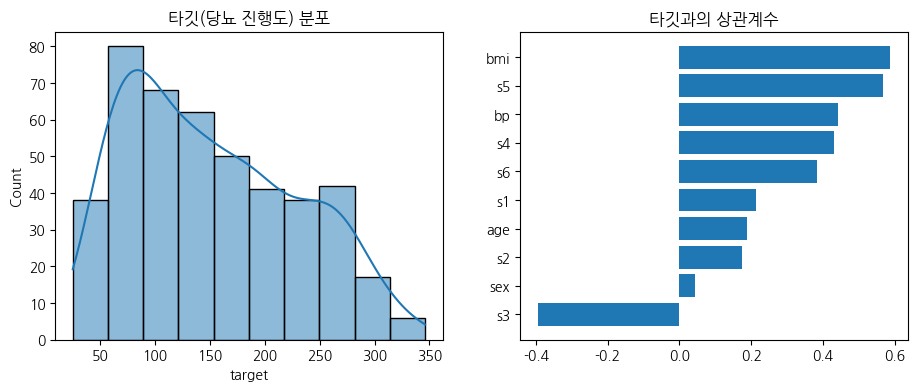

In [6]:
plt.figure(figsize=(11,4))
plt.subplot(121)
sns.histplot(df['target'], kde=True)
plt.title("타깃(당뇨 진행도) 분포")
plt.subplot(122)
plt.barh(corr.index, corr.values)
plt.title("타깃과의 상관계수")
plt.show()

In [7]:
best = corr.abs().idxmax()
print( best ) # 'bmi'

bmi


In [8]:
# ML 5단계 : 훈련/테스트 데이터 준비 -> ML 알고리즘 선택 -> 훈련 -> 평가 -> 예측

In [9]:
X_train, X_test, y_train, y_test = train_test_split(df[[best]], df['target'], test_size=0.2, random_state=42)

In [10]:
model = LinearRegression()

In [11]:
model.fit(X_train, y_train)

LinearRegression()

In [12]:
pred = model.predict(X_test) # 예측값

In [13]:
print(f"특성: {best}, R^2: {r2_score(y_test, pred):.3f}, MAE: {mean_absolute_error(y_test, pred):.1f}")

특성: bmi, R^2: 0.233, MAE: 52.3


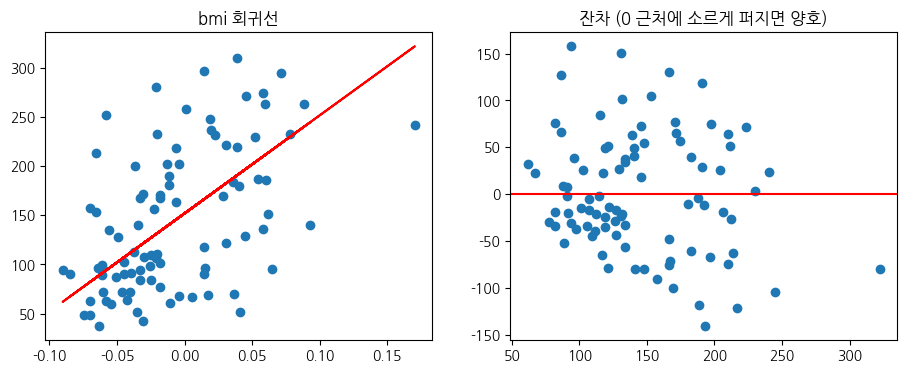

In [14]:
plt.figure(figsize=(11,4))
plt.subplot(121)
plt.scatter(X_test, y_test)
plt.plot(X_test, pred, color='red')
plt.title(f"{best} 회귀선")
plt.subplot(122)
plt.scatter(pred, y_test - pred)
plt.axhline(0, color='red')
plt.title("잔차 (0 근처에 소르게 퍼지면 양호)")
plt.show()

In [15]:
# end